# NARX Showcase

Julia version of the Python showcase [`NARX_showcase.ipynb`](https://github.com/mariesteinacker/NARX-Hematox) by M. Steinacker, Y. Kheifetz and M. Scholz (preprint: https://doi.org/10.1101/2024.08.06.606816). The training pipeline is in [`training.jl`](training.jl).

In [1]:
using Pkg
Pkg.activate(@__DIR__)
using NarxHematox
using DataFrames, Random, Plots

  Activating project at `~/Projects/PhD/NarxHematox.jl/examples`


# Simulate patient time series

We create a simulated patient time series with the Friberg model to showcase NARX learning and modeling.

## Friberg parameters

The patient's Friberg parameters (gamma, MTT in h, slope, c0 in 10⁹ cells/l) are taken from the Python showcase, where they were drawn from truncated normal distributions around the population parameters (`random_state=0`).

In [2]:
Random.seed!(0)
pat_p = [0.3222668, 217.17298364, 2.10676328, 276.05649911]

4-element Vector{Float64}:
   0.3222668
 217.17298364
   2.10676328
 276.05649911

## Generic treatment

We simulate 6 cycles of a 21-day treatment with the same dose each time, as for six cycles of CHOP-21 in the publication. Measurements are taken every 4 days.

In [3]:
therapy = (collect(0:5) .* 21, ones(6))
t_arr = collect(0:4:124)
t = collect(0:124);

## Patient time series with the Friberg model

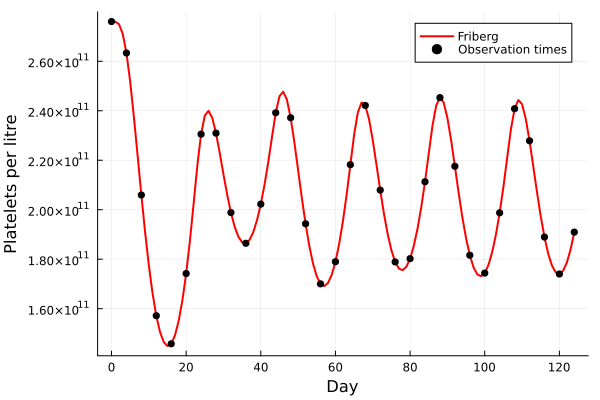

In [4]:
y_raw = friberg(pat_p, t_arr, therapy)
y_o = friberg(pat_p, t, therapy)

plot(t, y_o; label = "Friberg", color = :red, linewidth = 2,
     xlabel = "Day", ylabel = "Platelets per litre", legend = :best)
scatter!(t_arr, y_raw; label = "Observation times", color = :black)

## Noise and cumulative toxicity

To showcase transfer learning, we add noise and a cumulative toxicity pattern, so the simulated patient combines a pattern from the Friberg model with an individual pattern. This is only a demonstration of NARX modeling, not a realistic patient. Julia's random numbers differ from Python's, so the noisy observations differ slightly from the Python showcase.

For comparison, the plot includes the NCI thrombocytopenia degrees (TD).

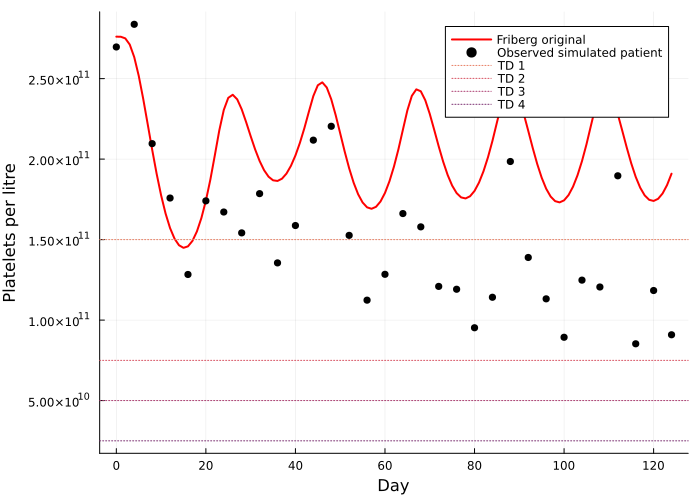

In [5]:
rng = Xoshiro(0)
trend = (1 .- exp.(-range(0, 1; length = length(t))))[t_arr .+ 1]
y_arr = y_raw .+ 0.1 .* y_raw .* randn(rng, length(y_raw)) .- trend .* y_raw[1] .* 0.5

td_colors = ["#e77e63", "#d64f5f", "#aa3a6e", "#7a2e70"]
plot(t, y_o; label = "Friberg original", color = :red, linewidth = 2, size = (700, 500),
     xlabel = "Day", ylabel = "Platelets per litre", legend = :best)
scatter!(t_arr, y_arr; label = "Observed simulated patient", color = :black)
for (i, level) in enumerate([1.5e11, 7.5e10, 5e10, 2.5e10])
    hline!([level]; label = "TD $i", color = td_colors[i], linestyle = :dot)
end
current()

## Simulated patient dataset

The observations with their cycle number.

In [6]:
df_p = DataFrame(Y = y_arr ./ 1e9, TIME = t_arr, CYCLE = div.(t_arr, 21) .+ 1)

Row,Y,TIME,CYCLE
,Float64,Int64,Int64
1,269.654,0,1
2,283.734,4,1
3,209.61,8,1
4,175.821,12,1
5,128.336,16,1
6,174.051,20,1
7,167.132,24,2
8,154.175,28,2
9,178.551,32,2


## Learning scenario

The first 4 cycles are available for learning; cycles 5 and 6 are used for testing.

In [7]:
train_cycles = 4
df_c = df_p[df_p.CYCLE .<= train_cycles, :]
split_day = df_c.TIME[end] + 1

81

# Friberg calibration

For transfer learning and comparison, we calibrate the Friberg model to the learning part of the simulated patient.

Calibrated Friberg parameters: [0.3346, 229.3, 2.36, 248.9]


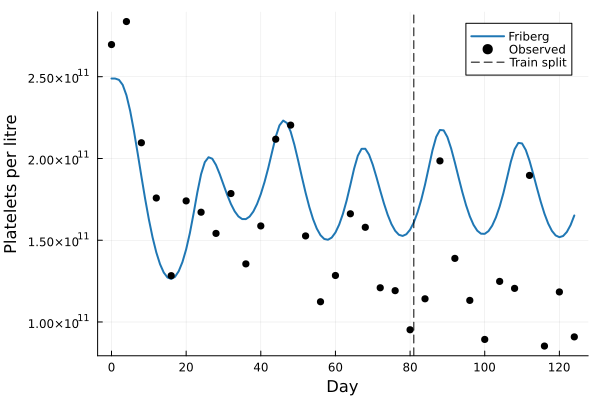

In [8]:
pc = calibrate_friberg(t_arr, y_arr, df_p.CYCLE, therapy; train_cycles = train_cycles)
y_fri = friberg(pc, t, therapy)

println("Calibrated Friberg parameters: ", round.(pc; sigdigits = 4))
plot(t, y_fri; label = "Friberg", color = "#1f77b4", linewidth = 2,
     xlabel = "Day", ylabel = "Platelets per litre", legend = :best)
scatter!(t_arr, y_arr; label = "Observed", color = :black)
vline!([split_day]; label = "Train split", color = :black, linestyle = :dash)

# NARX modeling

We train an ARX-GRU with the hyperparameters of the Python showcase (`default_hp`). Training starts from the weights of the index patient, a simulated patient with the population-average Friberg parameters, which speeds up training immensely. It then runs in three phases (see [`training.jl`](training.jl)):

1. Transfer learning on Friberg simulations of 8 treatment scenarios.
2. Fine-tuning the output layer on the patient.
3. Fine-tuning the full model on the patient.

This takes a few minutes.

In [9]:
hp = default_hp("GRU")
res = train_patient(t_arr, y_arr, df_p.CYCLE, therapy; celltype = "GRU", train_cycles = train_cycles,
                    hp = hp, pc = pc, verbose = false);

# Comparison

## Metrics

Step-MSE on the log scale over the test cycles (lower is better).

In [10]:
println("NARX:    ", round(res.smse_narx; sigdigits = 3))
println("Friberg: ", round(res.smse_fri; sigdigits = 3))

NARX:    0.0107
Friberg: 0.0564


## Comparison plot

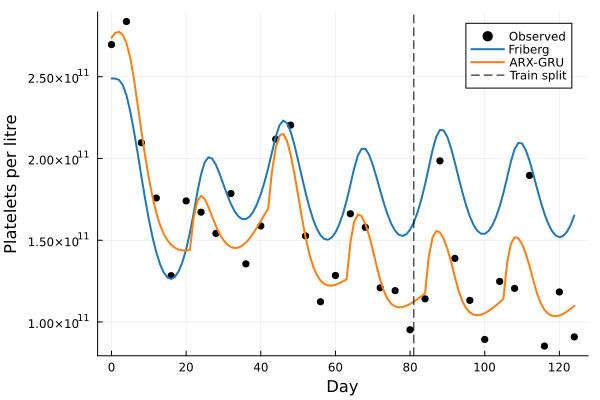

In [11]:
scatter(t_arr, y_arr; label = "Observed", color = :black,
        xlabel = "Day", ylabel = "Platelets per litre", legend = :best)
plot!(res.t, res.y_fri; label = "Friberg", color = "#1f77b4", linewidth = 2)
plot!(res.t, res.y_narx; label = "ARX-GRU", color = "#ff7f0e", linewidth = 2)
vline!([res.split_day]; label = "Train split", color = :black, linestyle = :dash)